# Phase 2 — Linear Dynamical System (LDS-SSM)
**Team 15 | Dynamical Systems in Machine Learning | West University of Timișoara**

**Goal.** Implement, train, and evaluate the **linear Gaussian state-space model** (LDS-SSM) using the synthetic datasets from Phase 1. This is the **baseline** against which we will later compare a nonlinear PLRNN-SSM.

This notebook is intended to be educational and self-contained *as an experiment*. Its reusable implementation lives in `src/models/lds.py`, not in notebook cells.

**Reference:** Koppe et al. (2019), *Identifying nonlinear dynamical systems via generative recurrent neural networks with applications to fMRI*, especially Eqs. (1)–(2) and Fig. 5.

## 1. Model formulation

We assume there is a latent state $z_t \in \mathbb{R}^{M}$ and an observed time series $x_t \in \mathbb{R}^{D}$.

The LDS assumes **linear latent dynamics** and **linear observations**:

$$
z_t = Fz_{t-1} + h + \varepsilon_t, \qquad \varepsilon_t \sim \mathcal{N}(0,Q),
$$

$$
x_t = Bz_t + \eta_t, \qquad \eta_t \sim \mathcal{N}(0,R).
$$

Here $F \in \mathbb{R}^{M\times M}$ is the transition matrix, $h$ is a bias, $B \in \mathbb{R}^{D\times M}$ maps latent states into observations, and $Q$, $R$ are diagonal noise covariance matrices. In the paper, $F=A+W$ for the **linear** baseline after replacing the nonlinear transfer function with the identity.

**What is learned?** $F$, $h$, $B$, $Q$ and $R$. **What is hidden?** The states $z_t$.

This implementation is an independently developed **linear Gaussian EM baseline**, not a port of the full nonlinear EM+annealing algorithm from the paper.

## 2. Parameter estimation: Kalman + EM

Our training loop is based on **Expectation-Maximization (EM)**:

1. **E-step:** given current parameters, run a Kalman filter and a Rauch–Tung–Striebel (RTS) smoother to estimate $p(z_{1:T}\mid x_{1:T})$ and the lagged covariance terms.
2. **M-step:** use those expected sufficient statistics to update the state transition and observation parameters using weighted least squares. Update the diagonal noise variances from the expected residual covariance.
3. Repeat until the requested maximum number of iterations or convergence.

We initialize the latent coordinate system with PCA, enforce a transition spectral radius below 1, and use lower bounds on noise variances. Therefore the algorithm is *constrained/generalized EM*: the objective is not mathematically guaranteed to improve after every step.

**Why not simply train $x_{t+1}=Fx_t$?** That would be an observed autoregression, not an LDS with inferred latent states and an explicit observation model.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

# Works from the repository root or from the notebooks/ subdirectory.
possible_roots = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next((p for p in possible_roots
                     if (p / 'src' / 'models' / 'lds.py').exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open this notebook inside the Phase-1/Phase-2 repository.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print('Repository:', PROJECT_ROOT)

from src.data.preprocessing import load_dataset
from src.models.lds import LinearGaussianSSM
from src.training.run_lds import run_lds_experiments


Repository: c:\PLRNN-Project


## 3. Load the datasets from Phase 1

The first 70% of the samples were standardized using only training statistics. The observations contain *measurement noise*, while `x_true` contains the standardized clean simulated trajectory. We will train on `x_obs`, not on the clean states.

In [2]:
dataset_dir = PROJECT_ROOT / 'data' / 'synthetic'
for system in ['van_der_pol', 'lorenz']:
    dataset = load_dataset(dataset_dir / f'{system}_seed42.npz')
    print(f'{system:>12s}: x_obs={dataset["x_obs"].shape}, '
          f'train_end={int(dataset["train_end"])}')
    assert np.isfinite(dataset['x_obs']).all()
    assert int(dataset['train_end']) == 700


 van_der_pol: x_obs=(1000, 2), train_end=700
      lorenz: x_obs=(1000, 3), train_end=700


## 4. Train the LDS models and evaluate held-out forecasts

For **van der Pol** we use $M=2$ latent states; for **Lorenz**, $M=3$. This baseline intentionally matches the number of observed and latent dimensions, but we will evaluate dimensions more systematically when comparing with PLRNNs.

For each prediction horizon $h\in\{1,5,10,20\}$, we estimate $z_t$ using the **causal** Kalman filter, then evolve it for $h$ steps without using any future observation. The target $x_{t+h}$ is always in the test interval.

As a simple reference, **persistence** predicts $\widehat{x}_{t+h}=x_t$. We also generate an entirely independent autonomous trajectory initialized using the final **training** state only.

In [3]:
# Trains two models and saves figures/JSON/NPZ under results/.
# On a slower machine the numerical Kalman EM loop may take a little time.
metrics = run_lds_experiments(
    data_dir=dataset_dir,
    fig_dir=PROJECT_ROOT / 'results' / 'figures',
    metrics_dir=PROJECT_ROOT / 'results' / 'metrics',
    n_iter=35,
    seed=42,
)



--- van_der_pol: training LDS (700/1000 samples) ---
EM step  1: log likelihood= 395.20, spectral radius=0.9892
EM step 10: log likelihood= 636.48, spectral radius=0.9923
EM step 20: log likelihood= 644.31, spectral radius=0.9918
EM step 30: log likelihood= 648.47, spectral radius=0.9917
EM step 35: log likelihood= 650.31, spectral radius=0.9917
horizon      LDS-MSE    Persistence-MSE
    1        0.0236        0.0273
    5        0.1308        0.1966
   10        0.3131        0.5714
   20        0.4560        1.1532

--- lorenz: training LDS (700/1000 samples) ---
EM step  1: log likelihood= 322.04, spectral radius=0.9657
EM step 10: log likelihood= 689.09, spectral radius=0.9750
EM step 20: log likelihood= 720.51, spectral radius=0.9737
EM step 30: log likelihood= 738.54, spectral radius=0.9736
EM step 35: log likelihood= 746.64, spectral radius=0.9736
horizon      LDS-MSE    Persistence-MSE
    1        0.0590        0.0531
    5        0.9315        0.7411
   10        2.9486    

## 5. Read the prediction error table

MSE is measured in the standardized observation space. **Lower is better** for forecasts. However, forecasts alone do not prove that the model has learned the original attractor. A model may be accurate for a few steps but fail to recreate the autonomous long-term dynamics.

In [4]:
print(f'{"System":<14} {"Method":<14} {"h=1":>9} {"h=5":>9} {"h=10":>9} {"h=20":>9}')
print('-'*72)
for system, record in metrics.items():
    for method, field in [('LDS-SSM', 'lds_mse'), ('Persistence', 'persistence_mse')]:
        values = record[field]
        print(f'{system:<14} {method:<14} ' +
              ' '.join(f'{values[str(h)]:9.4f}' for h in (1, 5, 10, 20)))
    print()


System         Method               h=1       h=5      h=10      h=20
------------------------------------------------------------------------
van_der_pol    LDS-SSM           0.0236    0.1308    0.3131    0.4560
van_der_pol    Persistence       0.0273    0.1966    0.5714    1.1532

lorenz         LDS-SSM           0.0590    0.9315    2.9486    5.5368
lorenz         Persistence       0.0531    0.7411    2.0920    3.2890



## 6. Inspect the learned dynamics

The important figures compare the **true attractor geometry** with new observations produced by the LDS **without further observation inputs**. We use consistent axis limits to avoid misleading visual comparisons.

A deterministic *stable* linear system typically converges to a fixed point or produces damped oscillations. It therefore cannot sustain the nonlinear limit cycle of van der Pol or the chaotic attractor of Lorenz.


 lds_van_der_pol.png


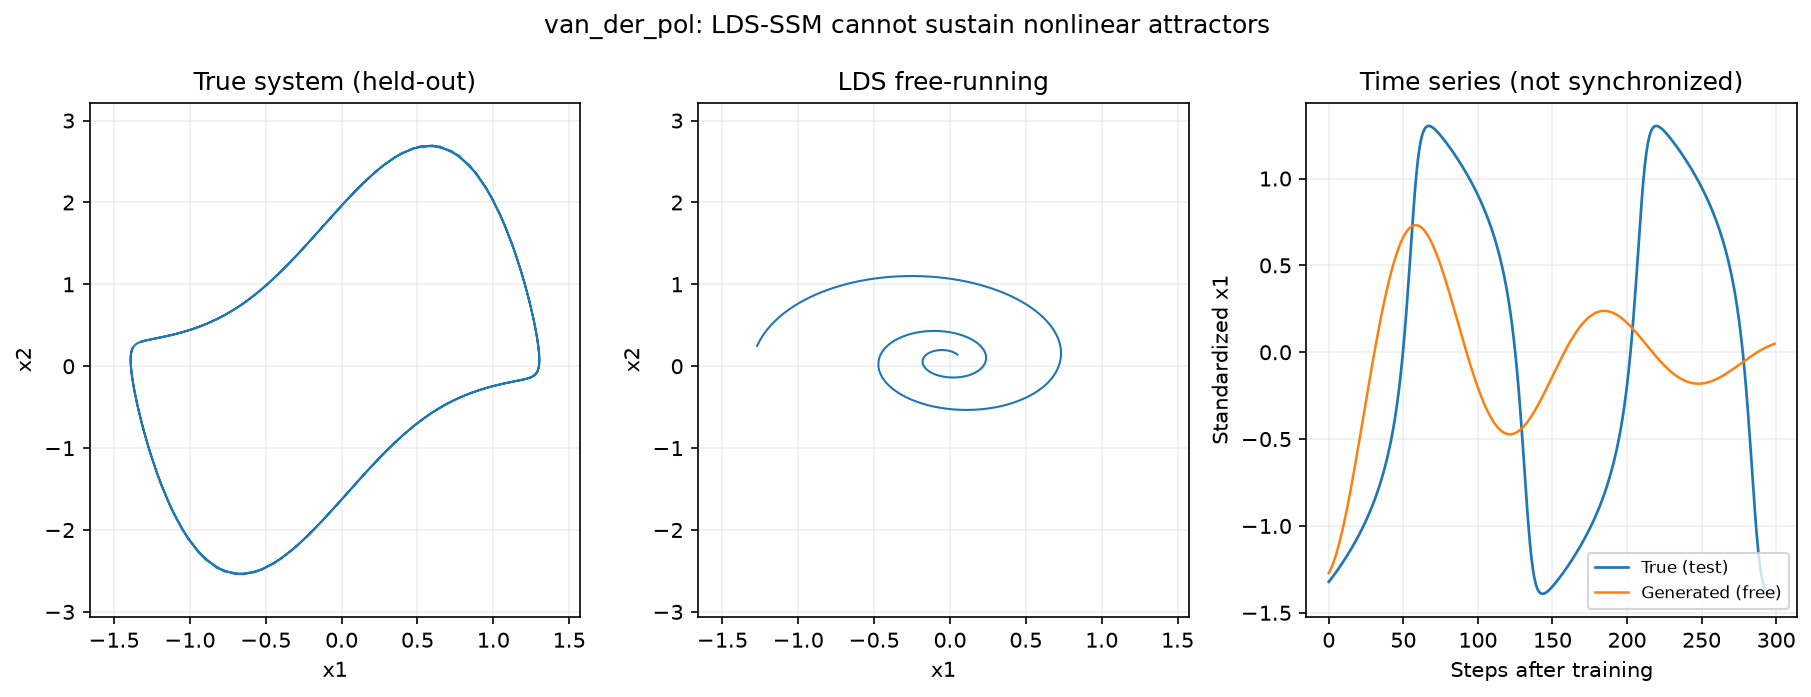


 lds_lorenz.png


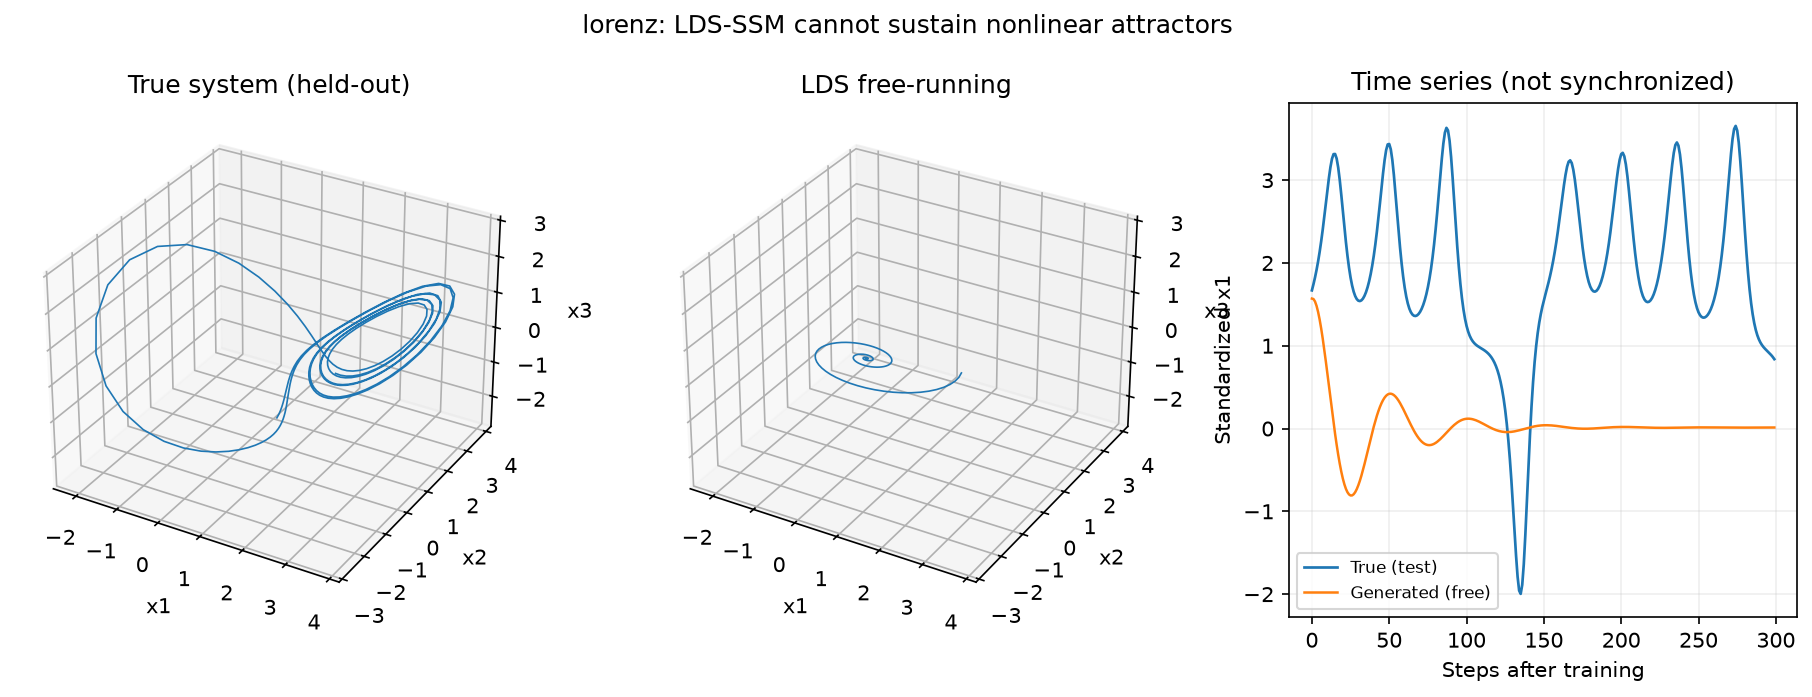


 lds_forecast_mse.png


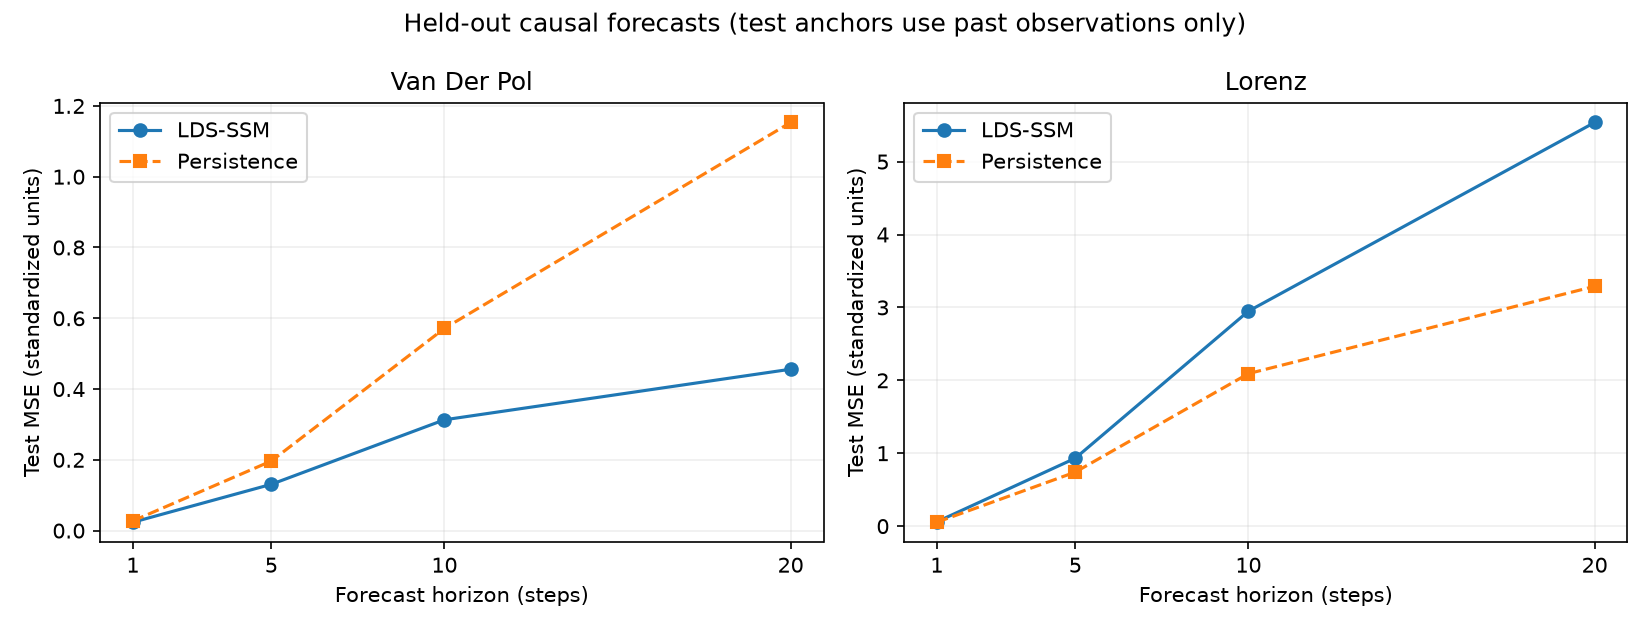


 lds_em_learning_curve.png


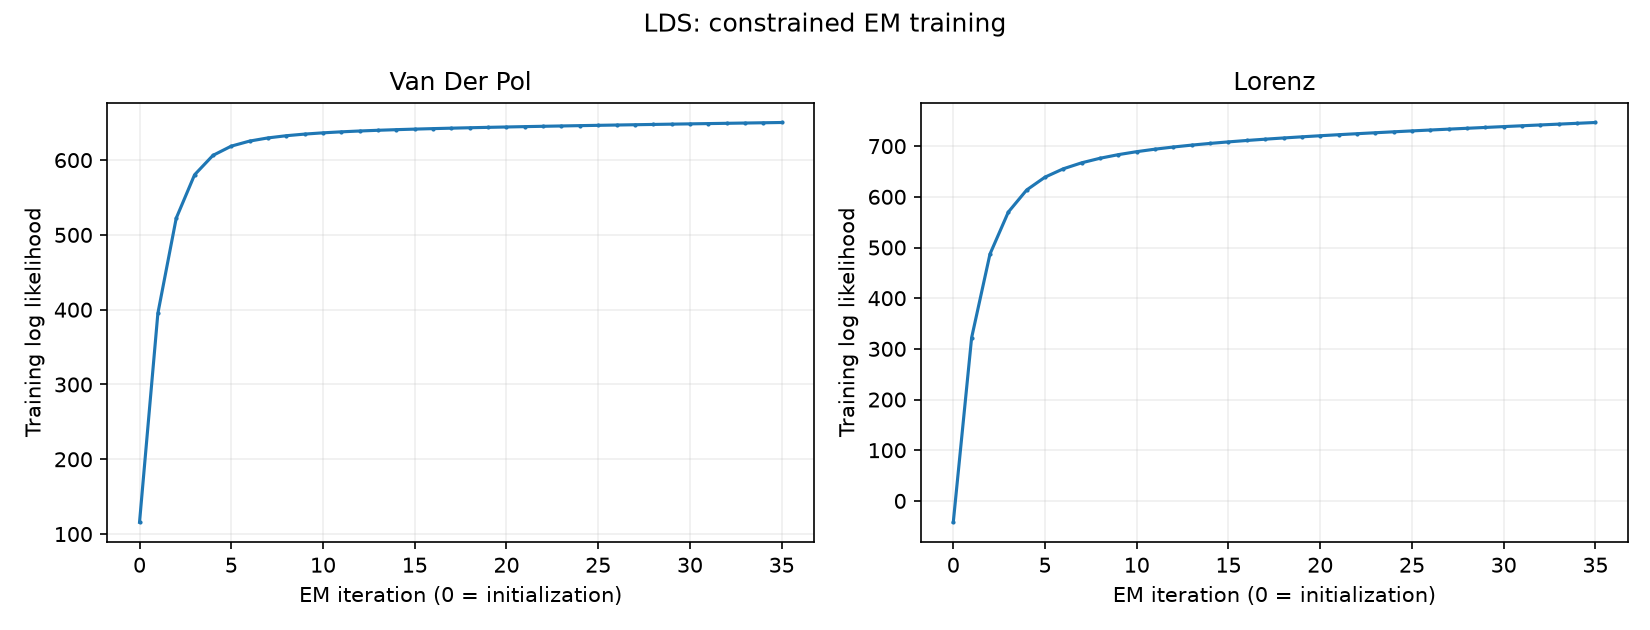

In [5]:
from IPython.display import Image, display

figure_dir = PROJECT_ROOT / 'results' / 'figures'
for name in ['lds_van_der_pol.png', 'lds_lorenz.png',
             'lds_forecast_mse.png', 'lds_em_learning_curve.png']:
    print('\n', name)
    display(Image(filename=str(figure_dir / name)))


## 7. Check stability of the estimated transition matrices

The **spectral radius** is $\rho(F)=\max_i |\lambda_i(F)|$. For our models we constrain $\rho(F)<1$. As a consequence, in autonomous deterministic generation with constant bias, the states tend toward a fixed point rather than a sustained chaotic trajectory.

This is a mathematical limitation of the stable linear model, and a useful motivation for studying the nonlinear PLRNN-SSM.

In [6]:
for system, record in metrics.items():
    print(f'{system}: spectral radius = {record["spectral_radius_F"]:.5f}, '
          f'initial LL = {record["training_log_likelihood_initial"]:.2f}, '
          f'final LL = {record["training_log_likelihood_final"]:.2f}, '
          f'EM updates = {record["n_em_iterations"]}')
    assert record['spectral_radius_F'] < 1.0
    assert np.isfinite(record['training_log_likelihood_final'])
print('Phase 2 validation completed.')


van_der_pol: spectral radius = 0.99168, initial LL = 115.78, final LL = 650.31, EM updates = 35
lorenz: spectral radius = 0.97364, initial LL = -42.11, final LL = 746.64, EM updates = 35
Phase 2 validation completed.


## 8. Interpretation and limitations

**Observations from this baseline:**

- The LDS can approximate local changes and give useful short-horizon forecasts for periodic data.
- On Lorenz, forecast accuracy deteriorates rapidly as the horizon grows. Our implementation can perform worse than a naive persistence predictor; this must be reported, not hidden.
- In autonomous deterministic generation, the LDS loses the nonlinear shape of the original attractor. A free-running LDS is not a nonlinear system identifier.

**Important limitations and next steps:**

1. This is a independently implemented **linear Gaussian LDS baseline** with stability constraints, not the paper's full EM/annealing protocol.
2. We currently use observation noise added by Phase 1, rather than the benchmark process-noise setting in the paper.
3. We have not evaluated KL divergence, Lyapunov exponents, or multiple independent seeds yet.
4. The next phase will implement a PLRNN and use equivalent data splits, latent dimensions, and evaluation conditions.
5. A *stochastic* LDS can continue fluctuating, even though its deterministic stable counterpart tends toward a fixed point; such fluctuations are not the same as a stable nonlinear limit cycle or chaos.

**Main conclusion:** *A linear state-space model is an informative predictive baseline, but a limited generative model of nonlinear dynamics.*